# 04 拥挤度：兴登堡预兆之外的另一个视角

兴登堡预兆只看价格分化。**拥挤度**看的是资金是否过度集中、交易是否过热：资金扎堆时，一旦有人开始卖，
容易踩踏式下跌。这个 notebook 用三个拥挤度指标回答三个问题：

1. 兴登堡信号出现时，市场是不是正处在拥挤状态？（检验「兴登堡 ≈ 抱团的价格投影」这个说法）
2. 「兴登堡集群 + 拥挤度高位」组合，相对基准率的超额，是否比单用兴登堡更大？
3. 拥挤度单独使用，能不能预警下跌，尤其是兴登堡看不见的 2015 年？

数据都从数据库读（`01_数据` 准备原始数据，`02_回测` 提供兴登堡信号），结果写回表 `crowding`、`crowding_test`。

## 0. 设置

In [1]:
import io
import os

import numpy as np
import pandas as pd
import sqlalchemy as sa
import matplotlib.pyplot as plt

DB_URL = os.getenv('HO_DB_URL', 'postgresql+psycopg://localhost/hindenburg')
engine = sa.create_engine(DB_URL)

TOP_SHARE = 0.05       # 成交额集中度：前 5% 的股票
HEAT_MA = 20           # 成交热度：全市场成交额的 20 日均值
CORR_WINDOW = 60       # 平均相关性：60 日滚动窗口
HIGH = 0.8             # 「高位」= 指标处于自身历史的前 20%
DD_WINDOWS = (21, 63, 252)
DD_CUTS = {'≥10%': -0.10, '≥20%': -0.20}

plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti SC', 'SimHei',
                                   'Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


def read_sql(sql: str, **kw) -> pd.DataFrame:
    """用 COPY 把查询结果读成 DataFrame（大表比 pd.read_sql 快很多）。"""
    buf = io.BytesIO()
    raw = engine.raw_connection()
    try:
        with raw.driver_connection.cursor() as cur:
            with cur.copy(f'COPY ({sql}) TO STDOUT WITH (FORMAT csv, HEADER)') as cp:
                for block in cp:
                    buf.write(block)
    finally:
        raw.close()
    buf.seek(0)
    return pd.read_csv(buf, float_precision='round_trip', **kw)


def copy_in(df: pd.DataFrame, table: str):
    raw = engine.raw_connection()
    try:
        pg = raw.driver_connection
        with pg.cursor() as cur:
            with cur.copy(f"COPY {table} ({', '.join(df.columns)}) FROM STDIN WITH (FORMAT csv, NULL '')") as cp:
                cp.write(df.to_csv(index=False, header=False, na_rep=''))
        pg.commit()
    finally:
        raw.close()


with engine.begin() as con:
    con.exec_driver_sql("""
    CREATE TABLE IF NOT EXISTS crowding (
        trade_date DATE PRIMARY KEY,
        amount_total DOUBLE PRECISION,   -- 全市场成交额，亿元
        conc_top5 DOUBLE PRECISION,      -- 成交额集中度（当日）
        conc_ma20 DOUBLE PRECISION,      -- 成交额集中度 20 日均值
        heat_ma20 DOUBLE PRECISION,      -- 全市场成交额 20 日均值，亿元
        avg_corr DOUBLE PRECISION,       -- 60 日隐含平均相关性
        conc_pct DOUBLE PRECISION,       -- 集中度在过去 3 年中的分位（0~1）
        heat_pct DOUBLE PRECISION,       -- 成交热度在过去 1 年中的分位
        corr_pct DOUBLE PRECISION);      -- 平均相关性在过去 3 年中的分位
    CREATE TABLE IF NOT EXISTS crowding_test (
        test TEXT, indicator TEXT, benchmark TEXT, window_days INTEGER, threshold TEXT,
        n INTEGER, hit_rate DOUBLE PRECISION, base_rate DOUBLE PRECISION, excess DOUBLE PRECISION);
    """)

## 1. 三个拥挤度指标

| 指标 | 怎么算 | 高说明什么 | 数据 |
|---|---|---|---|
| **成交额集中度** | 当天成交额排名前 5% 的股票，占全市场成交额的比例，取 20 日均值 | 资金扎堆少数股票（抱团） | tushare 成交额，2011 年起 |
| **成交热度** | 全市场成交额的 20 日均值，在过去 1 年中的分位 | 整体交易过热 | 同上 |
| **平均相关性** | 股票之间 60 日收益率的平均相关系数 | 齐涨齐跌，个股差异消失（全面拥挤） | 后复权价，2005 年起 |

「高位」= 指标处于**自身过去历史**的前 20%（集中度、相关性看过去 3 年，热度看过去 1 年），只用当天及以前的数据，没有前视偏差。
股票池与兴登堡的中证全指口径一致：沪深 A 股，剔除北交所。

### 1.1 成交额集中度与成交热度

In [2]:
amt = read_sql("SELECT trade_date, code, amount FROM stock_amount WHERE code NOT LIKE '%.BJ'",
               parse_dates=['trade_date'])
AMT = amt.pivot(index='trade_date', columns='code', values='amount').sort_index()
del amt
print(f'成交额：{AMT.index[0]:%Y-%m-%d} ~ {AMT.index[-1]:%Y-%m-%d}，{AMT.shape[0]:,} 天 × {AMT.shape[1]:,} 只')

vals = AMT.to_numpy(dtype=float)
n_traded = np.isfinite(vals).sum(axis=1)
k = np.ceil(TOP_SHARE * n_traded).astype(int)
desc = -np.sort(-np.nan_to_num(vals, nan=-np.inf), axis=1)          # 每天从大到小排序
desc[~np.isfinite(desc)] = 0
csum = np.cumsum(desc, axis=1)
top = csum[np.arange(len(k)), np.maximum(k, 1) - 1]
total = np.nansum(vals, axis=1)

cr = pd.DataFrame({'amount_total': total / 1e5,                     # 千元 → 亿元
                   'conc_top5': top / total}, index=AMT.index)
cr['conc_ma20'] = cr['conc_top5'].rolling(HEAT_MA).mean()
cr['heat_ma20'] = cr['amount_total'].rolling(HEAT_MA).mean()
cr['conc_pct'] = cr['conc_ma20'].rolling(756, min_periods=252).rank(pct=True)
cr['heat_pct'] = cr['heat_ma20'].rolling(252, min_periods=252).rank(pct=True)
cr[['amount_total', 'conc_top5', 'conc_ma20', 'heat_ma20']].describe().T

成交额：2011-01-04 ~ 2026-07-22，3,776 天 × 5,467 只


,count,mean,std,min,25%,50%,75%,max
amount_total,"3,776.0000","7,497.9249","6,231.3912",626.1167,"2,975.4619","6,033.8001","9,866.2985","39,411.2605"
conc_top5,"3,776.0000",0.3710,0.0576,0.2194,0.3355,0.3757,0.4082,0.5749
conc_ma20,"3,757.0000",0.3707,0.0533,0.2455,0.3410,0.3745,0.4031,0.5155
heat_ma20,"3,757.0000","7,459.7504","5,977.8458",735.3268,"2,956.9713","6,126.4200","9,678.1675","32,469.7240"


### 1.2 平均相关性

每天对 5,000 只股票算完整的相关矩阵太慢，这里用业界常用的**方差分解近似**（隐含平均相关性）：
等权组合的方差 = 个股方差的贡献 + 两两协方差的贡献，反解出平均相关系数。

```math
\bar\rho \approx \frac{\sigma_p^2 - \frac{1}{N^2}\sum_i \sigma_i^2}{\left(\frac{1}{N}\sum_i \sigma_i\right)^2 - \frac{1}{N^2}\sum_i \sigma_i^2}
```

其中 σ_p 是等权组合的 60 日波动率，σ_i 是个股的 60 日波动率。只用当天可交易（有成交、上市满一年）的股票，
单日涨跌幅截在 ±50% 以内，避免长期停牌复牌的跨期涨跌带偏结果。

In [3]:
px = read_sql("SELECT trade_date, code, close FROM stock_close_adj WHERE code NOT LIKE '%.BJ'",
              parse_dates=['trade_date'])
PX = px.pivot(index='trade_date', columns='code', values='close').sort_index()
PX = PX.loc[:, [str(c)[:6].isdigit() for c in PX.columns]]
del px
ok = read_sql('SELECT trade_date, code FROM stock_state WHERE status_t = 1 AND lenlist >= 365',
              parse_dates=['trade_date'])
VALID = pd.Series(True, index=pd.MultiIndex.from_frame(ok)).unstack(fill_value=False) \
          .reindex(index=PX.index, columns=PX.columns).astype('boolean').fillna(False).astype(bool)
del ok

ret = PX.pct_change(fill_method=None).where(VALID & VALID.shift(1, fill_value=False)).clip(-0.5, 0.5)
sig_i = ret.rolling(CORR_WINDOW, min_periods=40).std()
n = sig_i.notna().sum(axis=1)
sum_var = (sig_i ** 2).sum(axis=1)
mean_sig = sig_i.mean(axis=1)
sig_p = ret.mean(axis=1).rolling(CORR_WINDOW, min_periods=40).std()
corr = (sig_p ** 2 - sum_var / n ** 2) / (mean_sig ** 2 - sum_var / n ** 2)
corr = corr.where(n >= 100)
del ret, sig_i

CR = pd.concat([cr, corr.rename('avg_corr')], axis=1).sort_index()
CR['corr_pct'] = CR['avg_corr'].rolling(756, min_periods=252).rank(pct=True)
CR = CR.loc['2005-01-01':]
print(f'平均相关性：{CR.avg_corr.first_valid_index():%Y-%m-%d} 起，'
      f'中位数 {CR.avg_corr.median():.2f}，最高 {CR.avg_corr.max():.2f}（{CR.avg_corr.idxmax():%Y-%m-%d}）')

with engine.begin() as con:
    con.exec_driver_sql('DELETE FROM crowding')
copy_in(CR.rename_axis('trade_date').reset_index().assign(trade_date=lambda d: d.trade_date.dt.date)
        [['trade_date', 'amount_total', 'conc_top5', 'conc_ma20', 'heat_ma20', 'avg_corr',
          'conc_pct', 'heat_pct', 'corr_pct']], 'crowding')
print(f'已写入 crowding：{len(CR):,} 行')

平均相关性：2005-01-04 起，中位数 0.34，最高 0.77（2015-09-21）
已写入 crowding：5,245 行


## 2. 拥挤度和兴登堡信号放在一起看

中证全指走势（红色竖条 = 兴登堡有效集群），下面三张是三个拥挤度指标，灰色虚线是各自的「高位」线。

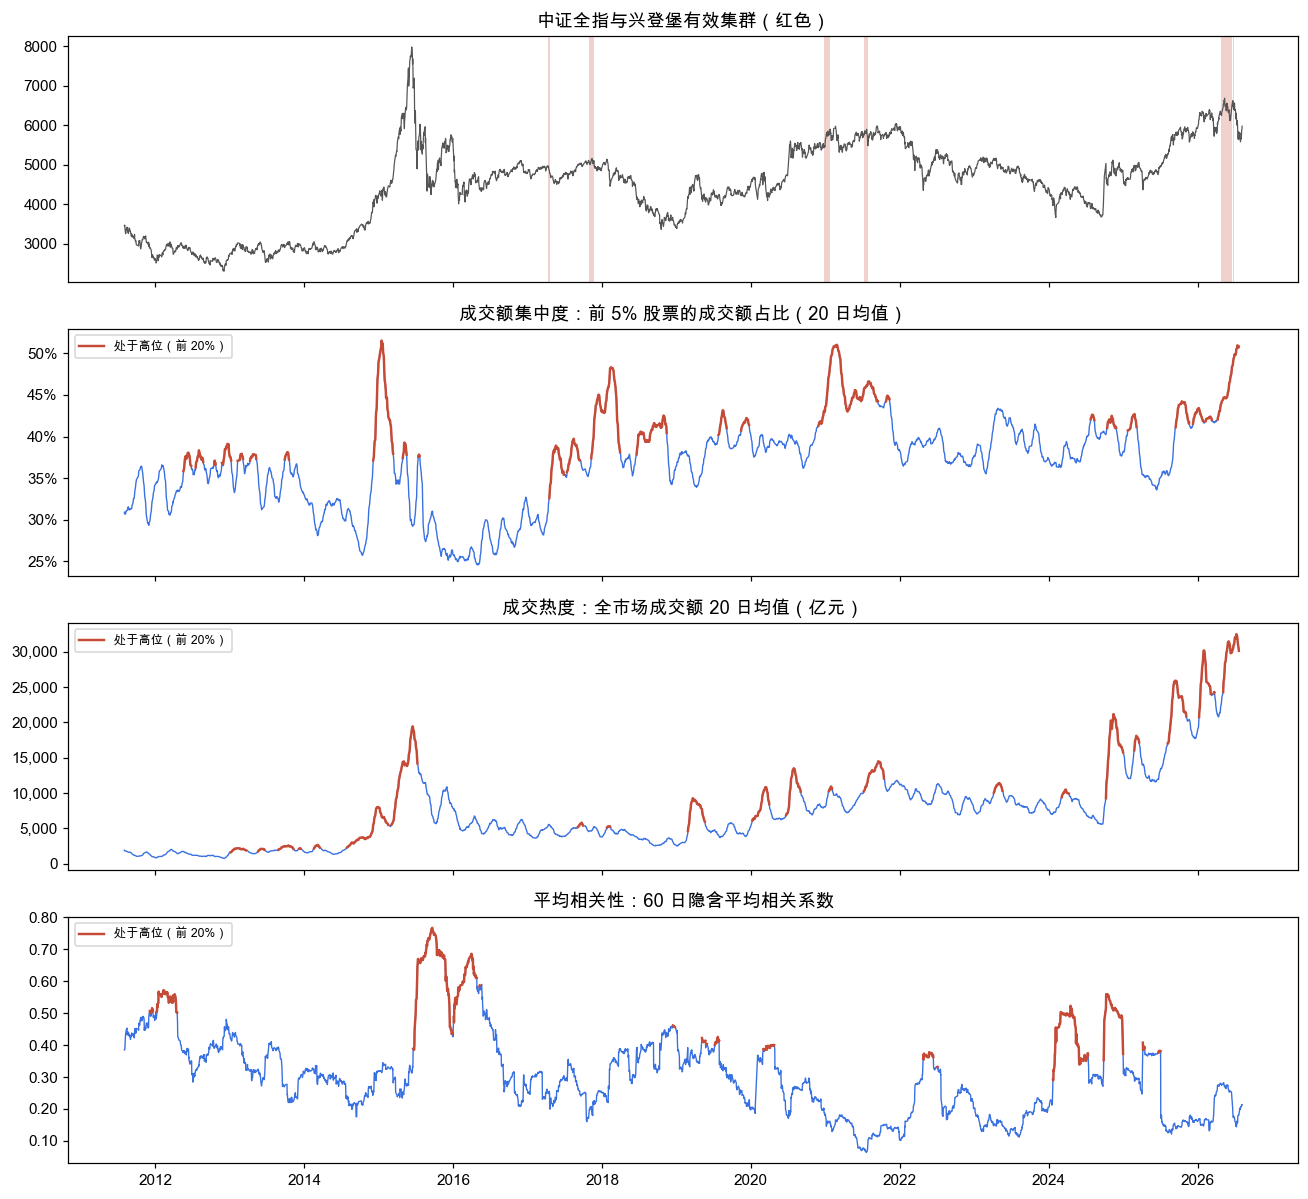

In [4]:
daily = read_sql("SELECT strategy, trade_date, index_close, signal FROM daily WHERE strategy IN ('ashare', 'general')",
                 parse_dates=['trade_date'])
clusters = read_sql("SELECT strategy, cluster_id, type, start_date, end_date, confirm_date, dd_21d, dd_63d, dd_252d, level "
                    "FROM clusters WHERE type = '有效集群'", parse_dates=['start_date', 'end_date', 'confirm_date'])
IDX = {k: g.set_index('trade_date')['index_close'] for k, g in daily.groupby('strategy')}
ash = IDX['ashare']
cl_a = clusters[clusters.strategy == 'ashare']

fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
view = CR.loc[ash.index[0]:]
ax = axes[0]
ax.plot(ash.index, ash, lw=0.8, color='#555')
for r in cl_a.itertuples():
    ax.axvspan(r.start_date, r.end_date, color='#C64B37', alpha=0.25, lw=0)
ax.set_title('中证全指与兴登堡有效集群（红色）')
for ax, col, pct, title, fmt in [
        (axes[1], 'conc_ma20', 'conc_pct', '成交额集中度：前 5% 股票的成交额占比（20 日均值）', lambda v, _: f'{v:.0%}'),
        (axes[2], 'heat_ma20', 'heat_pct', '成交热度：全市场成交额 20 日均值（亿元）', lambda v, _: f'{v:,.0f}'),
        (axes[3], 'avg_corr', 'corr_pct', '平均相关性：60 日隐含平均相关系数', lambda v, _: f'{v:.2f}')]:
    ax.plot(view.index, view[col], lw=0.9, color='#3971E1')
    hi = view[col].where(view[pct] >= HIGH)
    ax.plot(view.index, hi, lw=1.6, color='#C64B37', label=f'处于高位（前 {1 - HIGH:.0%}）')
    ax.yaxis.set_major_formatter(fmt)
    ax.set_title(title)
    ax.legend(loc='upper left', fontsize=8)
fig.tight_layout()

## 3. 问题一：兴登堡信号出现时，市场拥挤吗？

取五个指数所有有效集群的**确认日**，看当天三个拥挤度指标处在各自历史的什么分位，和全部交易日比较。
分位 0.5 = 处在历史中间；越接近 1 越拥挤。

In [5]:
conf = clusters.dropna(subset=['confirm_date']).copy()
at = CR.reindex(conf['confirm_date'].values)
conf[['conc_pct', 'heat_pct', 'corr_pct']] = at[['conc_pct', 'heat_pct', 'corr_pct']].values
names = {'conc_pct': '成交额集中度', 'heat_pct': '成交热度', 'corr_pct': '平均相关性'}
rows = []
for c, label in names.items():
    s_all = CR[c].dropna()
    s_sig = conf[c].dropna()
    rows.append({'指标': label, '集群数': len(s_sig), '信号时平均分位': s_sig.mean(), '全部交易日平均分位': s_all.mean(),
                 '信号时处于高位的比例': (s_sig >= HIGH).mean(), '全部交易日处于高位的比例': (s_all >= HIGH).mean()})
q1 = pd.DataFrame(rows).set_index('指标')
q1.style.format({c: '{:.0%}' for c in q1.columns if c != '集群数'})

,集群数,信号时平均分位,全部交易日平均分位,信号时处于高位的比例,全部交易日处于高位的比例
指标,,,,,
成交额集中度,65,79%,54%,63%,29%
成交热度,65,68%,54%,32%,26%
平均相关性,67,26%,46%,6%,17%


In [6]:
show = conf[conf.strategy == 'ashare'][['start_date', 'end_date', 'confirm_date', 'dd_252d', 'level',
                                         'conc_pct', 'heat_pct', 'corr_pct']].copy()
show.style.format({'dd_252d': '{:.1%}', 'conc_pct': '{:.0%}', 'heat_pct': '{:.0%}', 'corr_pct': '{:.0%}',
                   'start_date': '{:%Y-%m-%d}', 'end_date': '{:%Y-%m-%d}', 'confirm_date': '{:%Y-%m-%d}'}, na_rep='—')

,start_date,end_date,confirm_date,dd_252d,level,conc_pct,heat_pct,corr_pct
9,2017-04-10,2017-04-20,2017-04-12,-13.6%,中型回调,71%,70%,17%
10,2017-10-30,2017-11-21,2017-10-31,-34.8%,较大回撤,75%,44%,2%
11,2020-12-23,2021-01-25,2020-12-24,-11.0%,中型回调,92%,58%,5%
12,2021-07-08,2021-07-29,2021-07-15,-28.0%,较大回撤,94%,86%,0%
13,2026-03-03,2026-03-04,2026-03-04,—,近期信号,87%,84%,27%
14,2026-04-24,2026-06-18,2026-04-28,—,近期信号,99%,68%,54%
15,2026-06-22,2026-06-30,2026-06-23,—,近期信号,100%,96%,34%


## 4. 回撤计算与基准率

和 `02_回测` 同口径：从某天起未来 w 个交易日的**峰谷最大回撤**；基准率 = 每一天都当作信号日时的回撤概率。

In [7]:
def forward_dd(close: pd.Series, w: int) -> pd.Series:
    """每一天起、未来 w 个交易日（含当天）的峰谷最大回撤；数据不够的日子为 NaN。"""
    v = close.to_numpy(dtype=float)
    out = np.full(len(v), np.nan)
    for s in range(len(v) - w):
        seg = v[s:s + w + 1]
        out[s] = (seg / np.maximum.accumulate(seg) - 1).min()
    return pd.Series(out, index=close.index)


DD = {k: pd.DataFrame({w: forward_dd(c, w) for w in DD_WINDOWS}) for k, c in IDX.items()}
TESTS = []


def rate_table(test, indicator, bench, dates):
    """dates 这批日子在各窗口出现 ≥10% / ≥20% 回撤的比例，和全样本基准率对比。"""
    dd = DD[bench]
    rows = []
    for w in DD_WINDOWS:
        base_all = dd[w].dropna()
        sub = dd[w].reindex(dates).dropna()
        for th, cut in DD_CUTS.items():
            hit = (sub <= cut).mean() if len(sub) else np.nan
            base = (base_all <= cut).mean()
            rows.append({'test': test, 'indicator': indicator, 'benchmark': bench, 'window_days': w,
                         'threshold': th, 'n': len(sub), 'hit_rate': hit, 'base_rate': base, 'excess': hit - base})
    TESTS.extend(rows)
    return pd.DataFrame(rows)

## 5. 问题二：兴登堡集群 + 拥挤度高位

把五个指数观察期已满的有效集群放在一起，按确认日的拥挤度分成「高位」和「其他」两组，
比较 252 日内出现 ≥10% / ≥20% 回撤的比例，各自和对应指数的基准率相比。

In [8]:
grad = conf[conf.dd_252d.notna()].copy()
base = read_sql("SELECT strategy, threshold, base_all FROM hit_vs_base WHERE window_days = 252")
base = base.pivot(index='strategy', columns='threshold', values='base_all')
grad['base_10'] = grad.strategy.map(base['≥10%'])
grad['base_20'] = grad.strategy.map(base['≥20%'])
rows = []
for c, label in names.items():
    for grp, sub in (('高位', grad[grad[c] >= HIGH]), ('其他', grad[grad[c] < HIGH])):
        if not len(sub):
            continue
        rows.append({'指标': label, '分组': grp, '集群数': len(sub),
                     '命中率 ≥10%': (sub.dd_252d <= -0.10).mean(), '基准率 ≥10%': sub.base_10.mean(),
                     '命中率 ≥20%': (sub.dd_252d <= -0.20).mean(), '基准率 ≥20%': sub.base_20.mean()})
q2 = pd.DataFrame(rows).set_index(['指标', '分组'])
q2['超额 ≥10%'] = q2['命中率 ≥10%'] - q2['基准率 ≥10%']
q2['超额 ≥20%'] = q2['命中率 ≥20%'] - q2['基准率 ≥20%']
for (label, grp), r in q2.iterrows():
    TESTS.append({'test': '兴登堡集群+拥挤度', 'indicator': f'{label}·{grp}', 'benchmark': '五指数合并', 'window_days': 252,
                  'threshold': '≥20%', 'n': int(r['集群数']), 'hit_rate': r['命中率 ≥20%'],
                  'base_rate': r['基准率 ≥20%'], 'excess': r['超额 ≥20%']})
q2.style.format({c: '{:.0%}' for c in q2.columns if c != '集群数'})

## 6. 问题三：拥挤度单独使用能不能预警？

### 6.1 处于高位的日子

把三个指标各自处于高位的**所有交易日**当作信号日，看之后的回撤概率，和随便挑一天（基准率）比较。
注意相邻的日子高度重叠，有效样本远少于天数，看方向，不要看小数点。

In [9]:
res = []
for c, label in names.items():
    for bench, bname in (('ashare', '中证全指'), ('general', '上证综指')):
        dates = CR.index[(CR[c] >= HIGH)].intersection(IDX[bench].index)
        t = rate_table('拥挤度高位日', label, bench, dates)
        t['基准'] = bname
        res.append(t)
q3 = pd.concat(res)
q3 = q3[q3.window_days.isin([63, 252])].pivot_table(index=['indicator', '基准'], columns=['window_days', 'threshold'],
                                                     values='excess', sort=False)
q3.columns = [f'{w}日 {th} 超额' for w, th in q3.columns]
q3.style.format('{:+.0%}').background_gradient(cmap='RdBu_r', vmin=-0.3, vmax=0.3)

### 6.2 进入高位的事件

把「指标从非高位第一次升到前 10%」作为一个事件（距上一次事件至少 60 个交易日），
列出每个事件和之后中证全指 / 上证综指的回撤，看看历史上的大顶前有没有出现。

In [10]:
def events(col: str, level=0.9, gap=60) -> list:
    s = CR[col]
    hit = s >= level
    out, last = [], None
    for i, (d, h) in enumerate(hit.items()):
        if h and (i == 0 or not hit.iloc[i - 1]) and (last is None or i - last >= gap):
            out.append(d)
            last = i
    return out


ev_rows = []
for c, label in names.items():
    for d in events(c):
        bench = 'ashare' if d >= IDX['ashare'].index[0] else 'general'
        dd = DD[bench]
        pos = dd.index.searchsorted(d)
        if pos >= len(dd):
            continue
        r = dd.iloc[pos]
        ev_rows.append({'指标': label, '事件日': dd.index[pos].date(), '基准': '中证全指' if bench == 'ashare' else '上证综指',
                        '63日回撤': r[63], '252日回撤': r[252]})
EV = pd.DataFrame(ev_rows)
for c, label in names.items():
    sub = EV[EV['指标'] == label]
    print(f'{label}：{len(sub)} 个事件，252 日内 ≥20% 回撤 {int((sub["252日回撤"] <= -0.2).sum())} 次'
          f'（可评估 {int(sub["252日回撤"].notna().sum())} 次）')
EV.style.format({'63日回撤': '{:.1%}', '252日回撤': '{:.1%}'}, na_rep='观察中')

成交额集中度：18 个事件，252 日内 ≥20% 回撤 7 次（可评估 16 次）
成交热度：17 个事件，252 日内 ≥20% 回撤 5 次（可评估 14 次）
平均相关性：9 个事件，252 日内 ≥20% 回撤 6 次（可评估 9 次）


,指标,事件日,基准,63日回撤,252日回撤
0,成交额集中度,2012-05-23,中证全指,-13.0%,-22.3%
1,成交额集中度,2012-12-04,中证全指,-6.5%,-16.9%
2,成交额集中度,2013-04-23,中证全指,-16.9%,-16.9%
3,成交额集中度,2013-10-08,中证全指,-8.9%,-10.4%
4,成交额集中度,2014-12-08,中证全指,-5.7%,-46.8%
5,成交额集中度,2015-05-05,中证全指,-38.6%,-49.7%
6,成交额集中度,2017-05-05,中证全指,-3.5%,-13.6%
7,成交额集中度,2017-08-04,中证全指,-2.4%,-25.8%
8,成交额集中度,2017-11-16,中证全指,-13.3%,-34.5%
9,成交额集中度,2018-09-13,中证全指,-13.5%,-16.5%


### 6.3 2015 年：拥挤度看到了吗？

兴登堡在 2015 年一个信号都没有。看看 2015 年 6 月 12 日大顶前后，三个拥挤度指标在哪里。

In [11]:
probe = CR.loc['2015-03-01':'2015-08-31', ['conc_ma20', 'conc_pct', 'heat_ma20', 'heat_pct', 'avg_corr', 'corr_pct']]
probe.iloc[::10].style.format({'conc_ma20': '{:.1%}', 'conc_pct': '{:.0%}', 'heat_ma20': '{:,.0f}',
                               'heat_pct': '{:.0%}', 'avg_corr': '{:.2f}', 'corr_pct': '{:.0%}'})

,conc_ma20,conc_pct,heat_ma20,heat_pct,avg_corr,corr_pct
trade_date,,,,,,
2015-03-02 00:00:00,41.2%,94%,"5,324",79%,0.33,55%
2015-03-16 00:00:00,37.1%,78%,"6,200",86%,0.29,28%
2015-03-30 00:00:00,34.4%,47%,"9,351",100%,0.25,14%
2015-04-14 00:00:00,34.4%,47%,"12,449",100%,0.24,11%
2015-04-28 00:00:00,37.3%,79%,"14,306",100%,0.25,17%
2015-05-13 00:00:00,39.0%,91%,"14,073",97%,0.28,25%
2015-05-27 00:00:00,33.9%,40%,"14,702",100%,0.27,23%
2015-06-10 00:00:00,29.9%,12%,"18,349",100%,0.32,49%
2015-06-25 00:00:00,29.7%,11%,"18,090",96%,0.40,90%


结果写入数据库表 `crowding_test`：

In [12]:
with engine.begin() as con:
    con.exec_driver_sql('DELETE FROM crowding_test')
copy_in(pd.DataFrame(TESTS), 'crowding_test')
print(f'已写入 crowding_test：{len(TESTS)} 行')

已写入 crowding_test：42 行


## 7. 结论

**一、兴登堡预兆确实是「抱团」的价格投影。**

- 兴登堡集群确认时，**成交额集中度**有 63% 处在历史高位，而全部交易日只有 29%；平均分位 79%，远高于平时的 54%。
- 反过来，**平均相关性**在信号时普遍偏低：只有 6% 处在高位（平时 17%）。兴登堡需要个股走势分化，
  而高相关性意味着齐涨齐跌，两者天然互斥。
- 这直接验证了之前的推测：兴登堡能看到资金扎堆少数股票的结构性拥挤，看不到全面拥挤。

**二、叠加集中度高位，较大回撤的超额有改善，但样本很小。**

- 集中度高位时出现的兴登堡集群，252 日内 ≥20% 回撤的比例是 67%，基准率 51%，超额 +16 个百分点；
  其余集群是 42% 对 50%，超额 −8 个百分点。
- ≥10% 口径下两组没有差别（基准率本来就有 93%）。
- 这 21 个集群是五个指数合并的，同一轮行情会在几个指数里重复出现，有效样本远少于 21 个。方向值得继续跟踪，
  但还不能当作可靠的结论。成交热度高位的 +38 个百分点只有 8 个集群，更不能下结论。

**三、拥挤度单独使用，择时能力也不稳定。**

- 三个指标处于高位的日子，回撤概率相对基准率的超额有正有负，大多在 ±10 个百分点以内。
- **成交热度**在 2015 年 3 月底就升到历史最高分位，并一直维持到 6 月大顶：方向对了，但提前了两个多月，
  而且 2014 年 8 月、2015 年 1 月也各触发过一次，没法据此判断顶部在哪一天。
- **平均相关性**是滞后指标：2015 年它在 6 月 25 日（大顶之后两周）才进入高位，7 月以后升到 0.6~0.7；
  2008 年的几次事件也都发生在下跌途中。它刻画的是「踩踏正在发生」，不是「踩踏即将发生」。
- 2015 年的情况是：顶部前成交过热、但集中度低（12% 分位）、相关性也不高。这是全市场普涨的过热，
  不是抱团，所以兴登堡和集中度都看不到；只有成交热度给出了偏早的提示。

**总结**：拥挤度解释了兴登堡「什么时候会响」：资金抱团、个股分化的时候。它和集中度结合，也许能稍微提高
较大回撤的识别率，但样本太少，无法确认。三个拥挤度指标都不是可靠的独立择时工具。

**局限**：成交额数据从 2011 年开始，到 2026-07-22 为止；平均相关性用的是方差分解近似；
「高位」阈值（前 20%）和窗口长度都没有做稳健性检验，换参数结论可能变化。